Exploring a graph.

In [1]:
import requests, readline, sys, json
import numpy
import networkx as nx
import matplotlib as mpl
%matplotlib inline
%config InlineBacked.figure_format = 'svg'
import matplotlib.pyplot as plt
import matplotlib.cm as cmap
import seaborn

from query import *
from summary import *


vertexQ is a query to get all vertex labels:

In [2]:
vertexQ

'g.V().label().groupCount()'

getQuery gets the query results, and printResp prints a response

In [3]:
printResp(getQuery(vertexQ))


{'UnitDependency': '18378', 'UnnamedPipeObject': '67', 'MemoryObject': '4685', 'Event': '891421', 'FileObject': '3741', 'SrcSinkObject': '1079', 'Principal': '8', 'Subject': '110397', 'NetFlowObject': '3963'}


getGroupCountQuery runs a query and converts the resulting dictionary to a groupCount

In [4]:
getGroupCountQuery(vertexQ)

{'Event': 891421,
 'FileObject': 3741,
 'MemoryObject': 4685,
 'NetFlowObject': 3963,
 'Principal': 8,
 'SrcSinkObject': 1079,
 'Subject': 110397,
 'UnitDependency': 18378,
 'UnnamedPipeObject': 67}

getVertices collects the counts and number of incoming and outgoing edge labels for each vertex label.  For example:

In [5]:
vertices = getVertexSummary()
print (vertices)

Vertex types/counts:
{'UnitDependency': {'count': 18378, 'in': {}, 'out': {'unit': 18378, 'dependentUnit': 18378}}, 'UnnamedPipeObject': {'count': 67, 'in': {'predicateObject': 84812}, 'out': {}}, 'MemoryObject': {'count': 4685, 'in': {'predicateObject2': 2206, 'predicateObject': 8449}, 'out': {}}, 'Event': {'count': 891421, 'in': {}, 'out': {'predicateObject2': 2368, 'subject': 891421, 'predicateObject': 891421}}, 'FileObject': {'count': 3741, 'in': {'predicateObject2': 162, 'predicateObject': 195985}, 'out': {}}, 'SrcSinkObject': {'count': 1079, 'in': {'predicateObject': 481247}, 'out': {}}, 'Principal': {'count': 8, 'in': {'localPrincipal': 110397}, 'out': {}}, 'Subject': {'count': 110397, 'in': {'unit': 18378, 'parentSubject': 110330, 'subject': 891421, 'predicateObject': 110529, 'dependentUnit': 18378}, 'out': {'localPrincipal': 110397, 'parentSubject': 110330}}, 'NetFlowObject': {'count': 3963, 'in': {'predicateObject': 10399}, 'out': {}}}


Likewise, getEdges collects the counts of edge labels and the number of vertex labels on the source and target of each edge.

In [6]:
edges = getEdgeSummary()
print (edges)

Edge types/counts:
{'predicateObject2': {'count': 2368, 'in': {'MemoryObject': 2206, 'FileObject': 162}, 'out': {'Event': 2368}}, 'unit': {'count': 18378, 'in': {'Subject': 18378}, 'out': {'UnitDependency': 18378}}, 'localPrincipal': {'count': 110397, 'in': {'Principal': 110397}, 'out': {'Subject': 110397}}, 'parentSubject': {'count': 110330, 'in': {'Subject': 110330}, 'out': {'Subject': 110330}}, 'subject': {'count': 891421, 'in': {'Subject': 891421}, 'out': {'Event': 891421}}, 'predicateObject': {'count': 891421, 'in': {'UnnamedPipeObject': 84812, 'MemoryObject': 8449, 'FileObject': 195985, 'SrcSinkObject': 481247, 'Subject': 110529, 'NetFlowObject': 10399}, 'out': {'Event': 891421}}, 'dependentUnit': {'count': 18378, 'in': {'Subject': 18378}, 'out': {'UnitDependency': 18378}}}


Hmm.  Not very readable.  Let's try to do better.  printSummary takes a dictionary in one of the above forms and prints out the results in a more structured way.

In [7]:
printSummary(vertices)

{}
 -> 
UnitDependency[18378]
 -> 
{unit[18378],
dependentUnit[18378]}

{predicateObject[84812]}
 -> 
UnnamedPipeObject[67]
 -> 
{}

{predicateObject2[2206],
predicateObject[8449]}
 -> 
MemoryObject[4685]
 -> 
{}

{}
 -> 
Event[891421]
 -> 
{predicateObject2[2368],
subject[891421],
predicateObject[891421]}

{predicateObject2[162],
predicateObject[195985]}
 -> 
FileObject[3741]
 -> 
{}

{predicateObject[481247]}
 -> 
SrcSinkObject[1079]
 -> 
{}

{localPrincipal[110397]}
 -> 
Principal[8]
 -> 
{}

{unit[18378],
parentSubject[110330],
subject[891421],
predicateObject[110529],
dependentUnit[18378]}
 -> 
Subject[110397]
 -> 
{localPrincipal[110397],
parentSubject[110330]}

{predicateObject[10399]}
 -> 
NetFlowObject[3963]
 -> 
{}



How about for edges?

In [8]:
printSummary(edges)

{MemoryObject[2206],
FileObject[162]}
 -> 
predicateObject2[2368]
 -> 
{Event[2368]}

{Subject[18378]}
 -> 
unit[18378]
 -> 
{UnitDependency[18378]}

{Principal[110397]}
 -> 
localPrincipal[110397]
 -> 
{Subject[110397]}

{Subject[110330]}
 -> 
parentSubject[110330]
 -> 
{Subject[110330]}

{Subject[891421]}
 -> 
subject[891421]
 -> 
{Event[891421]}

{UnnamedPipeObject[84812],
MemoryObject[8449],
FileObject[195985],
SrcSinkObject[481247],
Subject[110529],
NetFlowObject[10399]}
 -> 
predicateObject[891421]
 -> 
{Event[891421]}

{Subject[18378]}
 -> 
dependentUnit[18378]
 -> 
{UnitDependency[18378]}



Now let's build and visualize a (bipartite) graph.  Nodes will represent either node or edge labels, and edges represent that a node can have an in-edge or out-edge with a given label (or vice versa).

In [9]:
G = nx.DiGraph()


In [10]:
G.add_nodes_from(vertices,bipartite=0)
G.add_nodes_from(edges,bipartite=1)

In [11]:
for v in vertices.keys():
    for e in vertices[v]['in'].keys():
        G.add_edge(e,v)
    for e in vertices[v]['out'].keys():
        G.add_edge(v,e)

In [12]:
nx.is_bipartite(G)

True

In [13]:
from networkx.algorithms import bipartite
bottom_nodes, top_nodes = bipartite.sets(G)
bottom_nodes,top_nodes

({'Event',
  'FileObject',
  'MemoryObject',
  'NetFlowObject',
  'Principal',
  'SrcSinkObject',
  'Subject',
  'UnitDependency',
  'UnnamedPipeObject'},
 {'dependentUnit',
  'localPrincipal',
  'parentSubject',
  'predicateObject',
  'predicateObject2',
  'subject',
  'unit'})

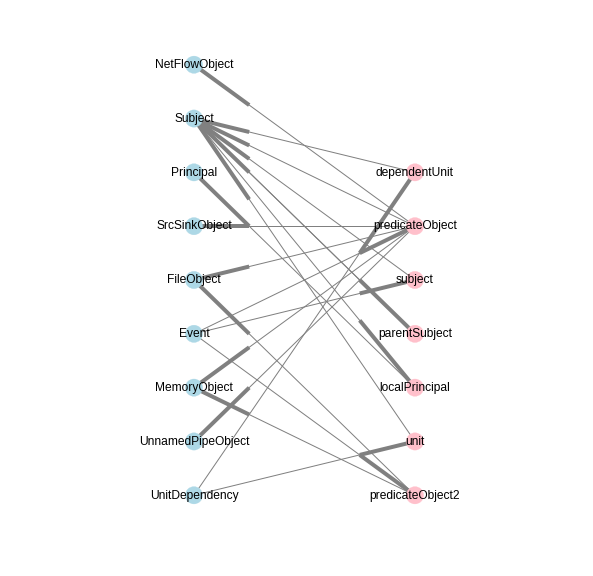

In [14]:
def showGraph(G):
    colors = ['lightblue' if d['bipartite']==0 else 'pink' for x,d in G.nodes(data=True)]
    positions = {}
    i = 1
    j = 1
    for x,d in G.nodes(data=True):
        if d['bipartite'] == 0:
            positions[x] = (3,i)
            i = i + 1
        else:
            positions[x] = (7,j)
            j = j + 1
    height = max(i,j)
    fig = plt.figure(figsize=(10,height))
    plt.gca().set_axis_off()   
    plt.gca().set_xlim([-0.05, height+0.05])    # add a little space around the plot
    plt.gca().set_ylim([-0.05, height+0.05])

    nx.draw_networkx(G,pos=positions,
                   with_labels=True,node_color=colors,edge_color='gray')

    _ = plt.show()

showGraph(G)

Consider the edge labels into and out of each node type and abstract them as +, *, 1, or ?

In [47]:
summarizeIncidences('Event')

{'in': {},
 'out': {'predicateObject': '1', 'predicateObject2': '?', 'subject': '1'}}

In [50]:

inferSchema(vertices.keys())

{'Event': {'in': {},
  'out': {'predicateObject': '1', 'predicateObject2': '?', 'subject': '1'}},
 'FileObject': {'in': {'predicateObject': '*', 'predicateObject2': '?'},
  'out': {}},
 'MemoryObject': {'in': {'predicateObject': '*', 'predicateObject2': '*'},
  'out': {}},
 'NetFlowObject': {'in': {'predicateObject': '+'}, 'out': {}},
 'Principal': {'in': {'localPrincipal': '+'}, 'out': {}},
 'SrcSinkObject': {'in': {'predicateObject': '*'}, 'out': {}},
 'Subject': {'in': {'dependentUnit': '*',
   'parentSubject': '*',
   'predicateObject': '*',
   'subject': '*',
   'unit': '*'},
  'out': {'localPrincipal': '1', 'parentSubject': '?'}},
 'UnitDependency': {'in': {}, 'out': {'dependentUnit': '1', 'unit': '1'}},
 'UnnamedPipeObject': {'in': {'predicateObject': '+'}, 'out': {}}}